# Notebook 4: Customer Segmentation (RFM Analysis)
**Business question:** Who are the most valuable customers, how many come back, and which groups should marketing target?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
IMAGES = Path("../images")
PROCESSED = Path("../data/processed")

master = pd.read_csv(PROCESSED / "orders_master.csv", parse_dates=["order_purchase_timestamp"])
master = master.dropna(subset=["payment_value"])
print("Orders:", len(master), "| Unique customers:", master["customer_unique_id"].nunique())

Orders: 96469 | Unique customers: 93349


In [2]:
snapshot_date = master["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
print("Snapshot date (the 'today' of the analysis):", snapshot_date.date())

rfm = master.groupby("customer_unique_id").agg(
    last_purchase = ("order_purchase_timestamp", "max"),
    frequency     = ("order_id", "nunique"),
    monetary      = ("payment_value", "sum"),
).reset_index()
rfm["recency"] = (snapshot_date - rfm["last_purchase"]).dt.days

rfm[["recency", "frequency", "monetary"]].describe().round(1)

Snapshot date (the 'today' of the analysis): 2018-08-30


,recency,frequency,monetary
count,93349.0,93349.0,93349.0
mean,237.9,1.0,165.2
std,152.6,0.2,226.3
min,1.0,1.0,9.6
25%,114.0,1.0,63.0
50%,219.0,1.0,107.8
75%,346.0,1.0,182.6
max,695.0,15.0,13664.1


In [3]:
print(rfm["frequency"].value_counts().sort_index())
print("\nRepeat customer rate:", round((rfm["frequency"] > 1).mean() * 100, 2), "%")

frequency
1     90548
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

Repeat customer rate: 3.0 %


In [4]:
# Recency: split into 5 equal groups. More recent = higher score (5 is best)
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# Monetary: 5 equal groups. Higher spend = higher score
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Frequency: rule-based, because almost everyone has exactly 1 order
rfm["F"] = np.select([rfm["frequency"] >= 3, rfm["frequency"] == 2], [3, 2], default=1)

rfm[["R", "F", "M"]].value_counts().head(10)

R  F  M
2  1  2    3968
1  1  2    3905
3  1  1    3903
1  1  1    3880
4  1  4    3757
      3    3740
5  1  4    3739
      1    3708
3  1  4    3698
5  1  3    3692
Name: count, dtype: int64

In [5]:
conditions = [
    (rfm["F"] >= 2) & (rfm["R"] >= 4),        # repeat buyers, bought recently
    (rfm["F"] >= 2),                          # repeat buyers, not recently
    (rfm["R"] >= 4) & (rfm["M"] >= 4),        # one order, recent, high spend
    (rfm["R"] >= 4),                          # one order, recent
    (rfm["R"] <= 2) & (rfm["M"] >= 4),        # one order, long ago, high spend
    (rfm["R"] <= 2),                          # one order, long ago
]
segments = [
    "Champions",
    "Loyal – lapsing",
    "Promising big spenders",
    "Recent one-timers",
    "At-risk big spenders",
    "Lost / hibernating",
]
rfm["segment"] = np.select(conditions, segments, default="Needs attention")
rfm["segment"].value_counts()

segment
Lost / hibernating        22488
Recent one-timers         21776
Needs attention           18105
Promising big spenders    14442
At-risk big spenders      13737
Loyal – lapsing            1592
Champions                  1209
Name: count, dtype: int64

In [6]:
seg = rfm.groupby("segment").agg(
    customers   = ("customer_unique_id", "count"),
    avg_recency = ("recency", "mean"),
    avg_orders  = ("frequency", "mean"),
    avg_spend   = ("monetary", "mean"),
    revenue     = ("monetary", "sum"),
)
seg["customer_share_%"] = (seg["customers"] / seg["customers"].sum() * 100).round(1)
seg["revenue_share_%"]  = (seg["revenue"] / seg["revenue"].sum() * 100).round(1)
seg = seg.round(1).sort_values("revenue", ascending=False)
seg

,customers,avg_recency,avg_orders,avg_spend,revenue,customer_share_%,revenue_share_%
segment,,,,,,,
Promising big spenders,14442,91.6,1.0,302.2,4363773.6,15.5,28.3
At-risk big spenders,13737,394.2,1.0,307.9,4229597.8,14.7,27.4
Needs attention,18105,220.5,1.0,151.3,2739994.6,19.4,17.8
Lost / hibernating,22488,396.1,1.0,72.7,1635175.6,24.1,10.6
Recent one-timers,21776,90.0,1.0,72.9,1588184.1,23.3,10.3
Loyal – lapsing,1592,319.9,2.1,298.2,474786.8,1.7,3.1
Champions,1209,89.2,2.2,322.2,389570.4,1.3,2.5


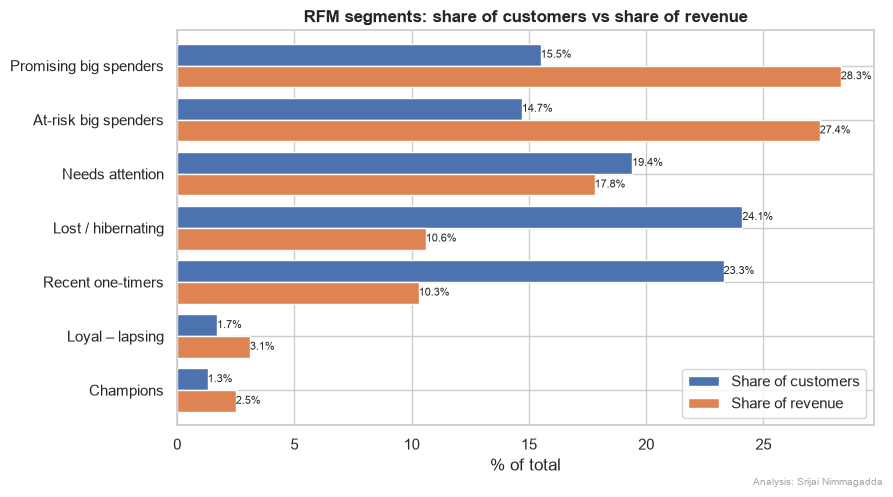

In [9]:
ax = seg[["customer_share_%", "revenue_share_%"]].plot(
    kind="barh", figsize=(9, 5), color=["#4C72B0", "#DD8452"], width=0.8
)
ax.invert_yaxis()
ax.set_xlabel("% of total")
ax.set_ylabel("")
ax.set_title("RFM segments: share of customers vs share of revenue", fontweight="bold")
ax.legend(["Share of customers", "Share of revenue"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=8)
plt.tight_layout()
plt.gcf().text(0.99, 0.01, "Analysis: Srijai Nimmagadda", ha="right", va="bottom", fontsize=7, color="gray", alpha=0.7)

plt.savefig(IMAGES / "04_rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
rfm.to_csv(PROCESSED / "rfm_segments.csv", index=False)
print("Saved rfm_segments.csv")

Saved rfm_segments.csv


## Key findings
1. **Low retention:** 97% of 93,349 customers ordered only once; the repeat customer rate is just 3.0%.
2. **Revenue concentration:** high-spending customers (Promising + At-risk big spenders) are 30.2% of customers but generate 55.7% of revenue.
3. **Biggest win-back opportunity:** 13,737 "At-risk big spenders" (avg spend R$308, inactive ~394 days) represent R$4.23M, 27.4% of total revenue.
4. **Repeat customers are worth ~2× more:** Champions and Loyal customers spend R$298–322 on average, against R$165 across all customers.
5. **Skewed spending:** median spend is R$108 against a mean of R$165, so a small number of large orders raises the average.

## Recommendations
- **Win-back campaign** for At-risk big spenders (personalised offers, reminders of categories they bought before).
- **Second-purchase incentive** for Recent one-timers and Promising big spenders within ~90 days of their first order.
- **Loyalty rewards** for Champions to keep the most engaged customers active.